# Question 2 — Verified OpenML credit-g classification

This is a stepwise development study using official OpenML ID 31, version 1. We inspect provenance, prepare mixed feature types, compare classifiers on training CV, measure three families of capacity control, and evaluate a preselected model. No test result chooses parameters.

In [1]:
from pathlib import Path
import sys, json, inspect
import numpy as np
import pandas as pd
root = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
assert (root / 'src').is_dir(), 'Run from the project root or notebooks directory'
sys.path.insert(0, str(root))
from IPython.display import display, Image
from src.data import load_data, NUMERIC
from src.q2_classification import split_data, make_pipeline, models, evaluate_cv, run_studies
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix

## Official artifact and schema
Raw ARFF bytes are checked against the official MD5 and recorded SHA-256 before parsing. Good credit is encoded as 0; bad credit as 1. The source is not a sklearn dataset reconstruction.

In [2]:
df = load_data(root)
provenance = json.loads((root / "data/metadata/provenance.json").read_text())
display(pd.Series({key:provenance[key] for key in ["dataset_id","dataset_version","dataset_name","raw_sha256","retrieved_at_utc"]}))
display(df.head());display(df.dtypes)
print("Rows, columns:", df.shape)
print("Missing cells, exact duplicates:", df.isna().sum().sum(), df.duplicated().sum())
display(df["class"].value_counts())

dataset_id                                                         31
dataset_version                                                     1
dataset_name                                                 credit-g
raw_sha256          768be84ef749110d5fcac109a6541f2df190e8c6987e1d...
retrieved_at_utc                     2026-10-09T13:00:45.773055+00:00
dtype: object

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6.0,critical/other existing credit,radio/tv,1169.0,no known savings,>=7,4.0,male single,none,...,real estate,67.0,none,own,2.0,skilled,1.0,yes,yes,good
1,0<=X<200,48.0,existing paid,radio/tv,5951.0,<100,1<=X<4,2.0,female div/dep/mar,none,...,real estate,22.0,none,own,1.0,skilled,1.0,none,yes,bad
2,no checking,12.0,critical/other existing credit,education,2096.0,<100,4<=X<7,2.0,male single,none,...,real estate,49.0,none,own,1.0,unskilled resident,2.0,none,yes,good
3,<0,42.0,existing paid,furniture/equipment,7882.0,<100,4<=X<7,2.0,male single,guarantor,...,life insurance,45.0,none,for free,1.0,skilled,2.0,none,yes,good
4,<0,24.0,delayed previously,new car,4870.0,<100,1<=X<4,3.0,male single,none,...,no known property,53.0,none,for free,2.0,skilled,2.0,none,yes,bad


checking_status               str
duration                  float64
credit_history                str
purpose                       str
credit_amount             float64
savings_status                str
employment                    str
installment_commitment    float64
personal_status               str
other_parties                 str
residence_since           float64
property_magnitude            str
age                       float64
other_payment_plans           str
housing                       str
existing_credits          float64
job                           str
num_dependents            float64
own_telephone                 str
foreign_worker                str
class                         str
dtype: object

Rows, columns: (1000, 21)
Missing cells, exact duplicates: 0 0


class
good    700
bad     300
Name: count, dtype: int64

## One stratified split, then exploratory analysis
No rows are removed because the verified source has no missing values or exact duplicates. EDA uses only development records. Large values are not automatically errors.

Development/test: (800, 20) (200, 20)


class
0    560
1    240
Name: count, dtype: int64

class
0    140
1     60
Name: count, dtype: int64

,duration,credit_amount,installment_commitment,residence_since,age,existing_credits,num_dependents
count,800.000000,800.00000,800.000000,800.00000,800.000000,800.000000,800.000000
mean,20.770000,3189.59125,2.941250,2.83000,35.323750,1.407500,1.160000
std,11.817325,2673.54737,1.124446,1.11137,11.045313,0.567315,0.366835
min,4.000000,276.00000,1.000000,1.00000,19.000000,1.000000,1.000000
25%,12.000000,1353.00000,2.000000,2.00000,27.000000,1.000000,1.000000
50%,18.000000,2317.00000,3.000000,3.00000,33.000000,1.000000,1.000000
75%,24.000000,3933.00000,4.000000,4.00000,41.000000,2.000000,1.000000
max,60.000000,15945.00000,4.000000,4.00000,75.000000,4.000000,2.000000


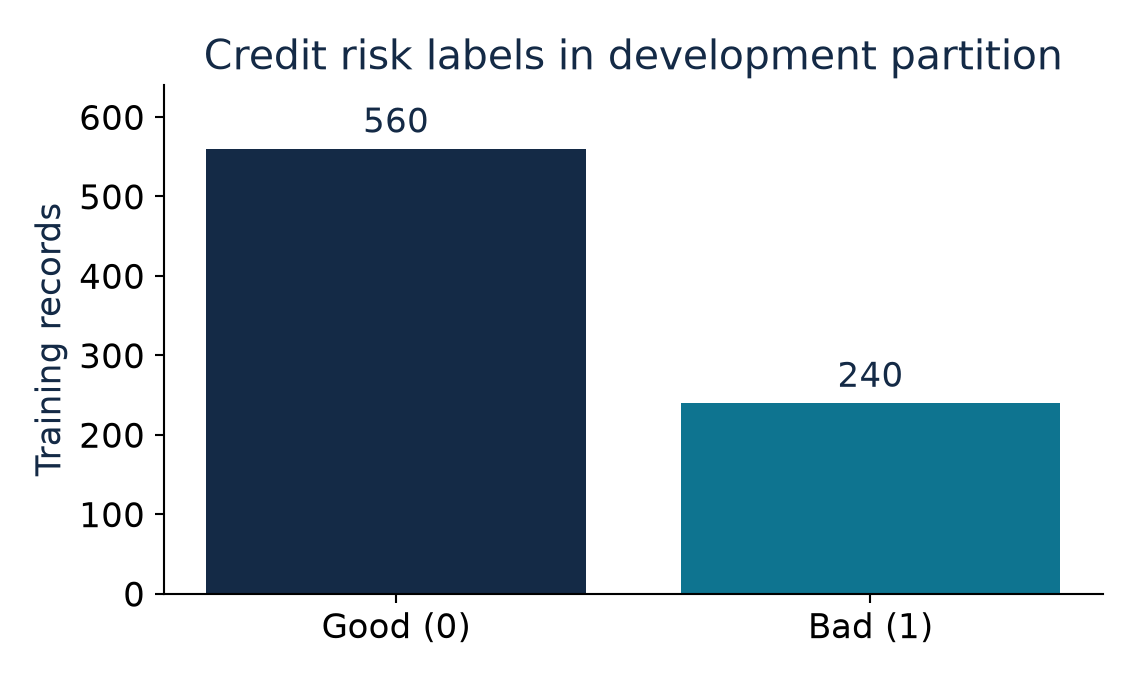

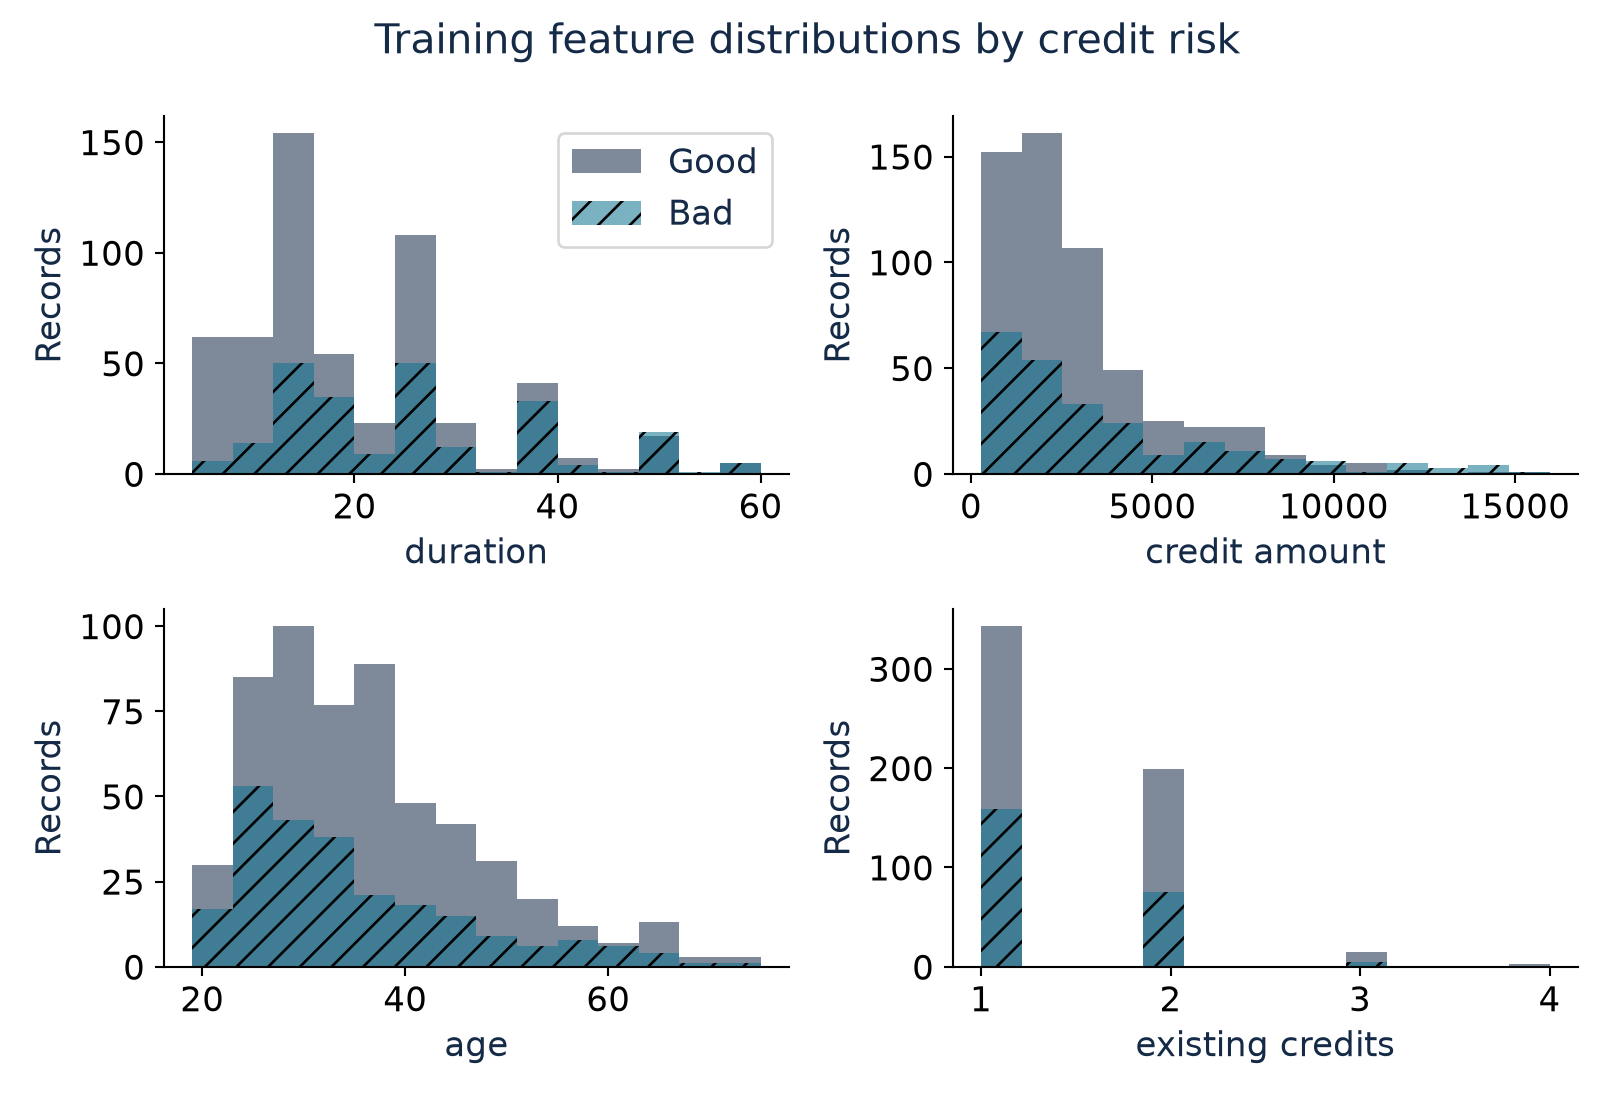

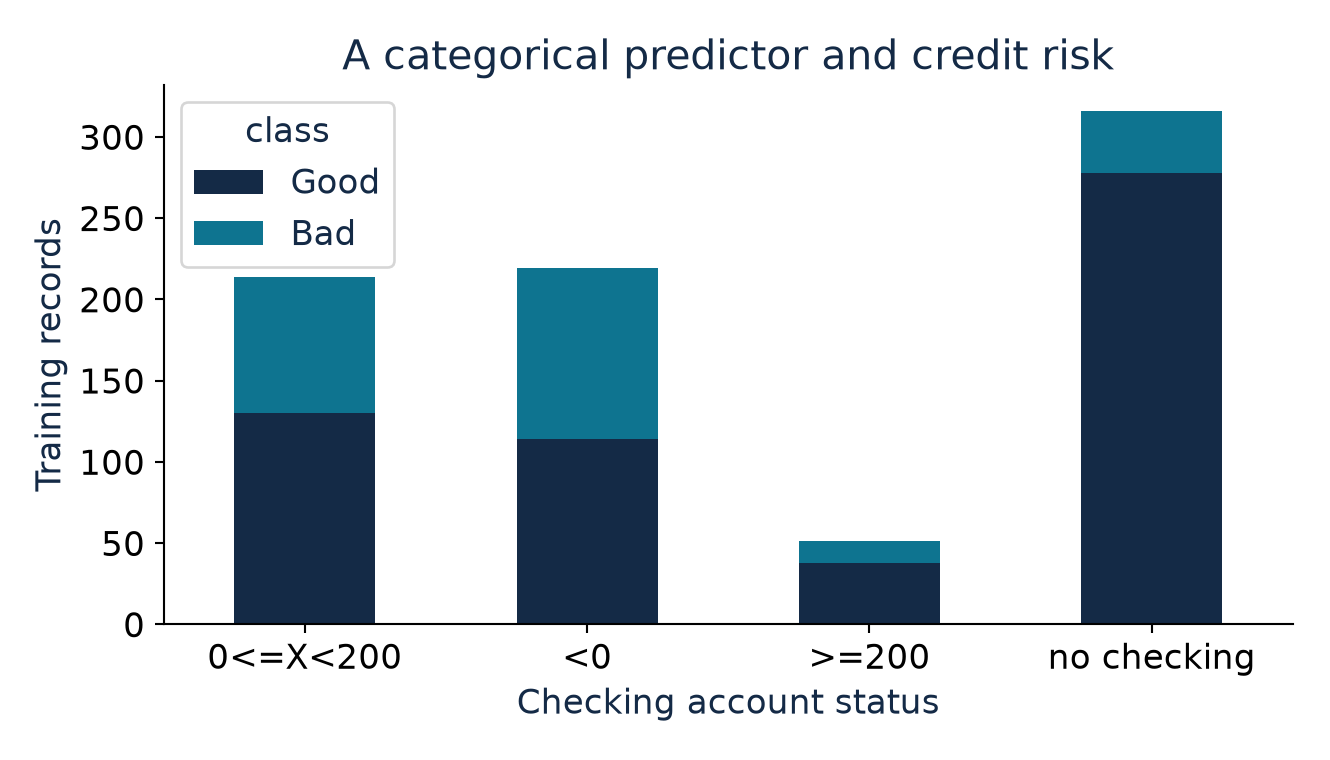

In [3]:
X_train, X_test, y_train, y_test = split_data(df)
print("Development/test:", X_train.shape, X_test.shape)
display(y_train.value_counts());display(y_test.value_counts())
display(X_train[NUMERIC].describe())
for name in ["q2_class_balance.png","q2_numeric_distributions.png","q2_categorical.png"]:
    display(Image(filename=str(root / "figures" / name), width=650))

## Inspect and fit the preparation pipeline
Numerical imputation and scaling learn development statistics; categorical imputation and one-hot categories learn development records. During CV this whole pipeline is refitted on each fold. The clean dataset does not need invented cleaning.

In [4]:
print(inspect.getsource(make_pipeline))
pipeline = make_pipeline(models()["Logistic Regression"], X_train).fit(X_train,y_train)
prep = pipeline.named_steps["preprocess"]
transformed = prep.transform(X_train)
print("Transformed training matrix:", transformed.shape)
assert np.isfinite(transformed).all()
np.testing.assert_allclose(prep.named_transformers_["numeric"].named_steps["scale"].mean_, X_train[NUMERIC].mean())
display(pd.Series(prep.get_feature_names_out()).head(20))

def make_pipeline(model, X):
    categorical = [c for c in X.columns if c not in NUMERIC]
    prep = ColumnTransformer(
        [
            (
                "numeric",
                Pipeline(
                    [
                        ("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler()),
                    ]
                ),
                NUMERIC,
            ),
            (
                "categorical",
                Pipeline(
                    [
                        ("impute", SimpleImputer(strategy="most_frequent")),
                        (
                            "encode",
                            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                        ),
                    ]
                ),
                categorical,
            ),
        ],
        sparse_threshold=0,
    )
    return Pipeline([("preprocess", prep), ("model", model)])

Transformed training matrix: (800,

0                                     numeric__duration
1                                numeric__credit_amount
2                       numeric__installment_commitment
3                              numeric__residence_since
4                                          numeric__age
5                             numeric__existing_credits
6                               numeric__num_dependents
7                 categorical__checking_status_0<=X<200
8                       categorical__checking_status_<0
9                    categorical__checking_status_>=200
10             categorical__checking_status_no checking
11                 categorical__credit_history_all paid
12    categorical__credit_history_critical/other exi...
13       categorical__credit_history_delayed previously
14            categorical__credit_history_existing paid
15      categorical__credit_history_no credits/all paid
16                        categorical__purpose_business
17              categorical__purpose_domestic ap

## Fixed-fold classifier comparison
Macro-F1 gives good and bad credit equal weight. All 12 predictive algorithms and the majority baseline use the same five development folds. Standard deviation is fold variation, not a confidence interval.

,model,cv_macro_f1_mean,cv_macro_f1_std,fold_train_macro_f1_mean,fold_generalization_gap
10,HistGradientBoosting,0.6844,0.0403,1.0000,0.3156
6,Extra Trees,0.6633,0.0583,1.0000,0.3367
7,Linear SVM,0.6624,0.0707,0.7326,0.0702
12,LDA,0.6617,0.0654,0.7274,0.0656
1,Logistic Regression,0.6582,0.0723,0.7277,0.0695
8,RBF SVM,0.6500,0.0510,0.8239,0.1740
9,Gradient Boosting,0.6404,0.0346,0.9110,0.2706
5,Random Forest,0.6389,0.0682,1.0000,0.3611
2,KNN,0.6316,0.0483,0.7415,0.1099
11,AdaBoost,0.6232,0.0348,0.6611,0.0380


Selected before test evaluation: HistGradientBoosting


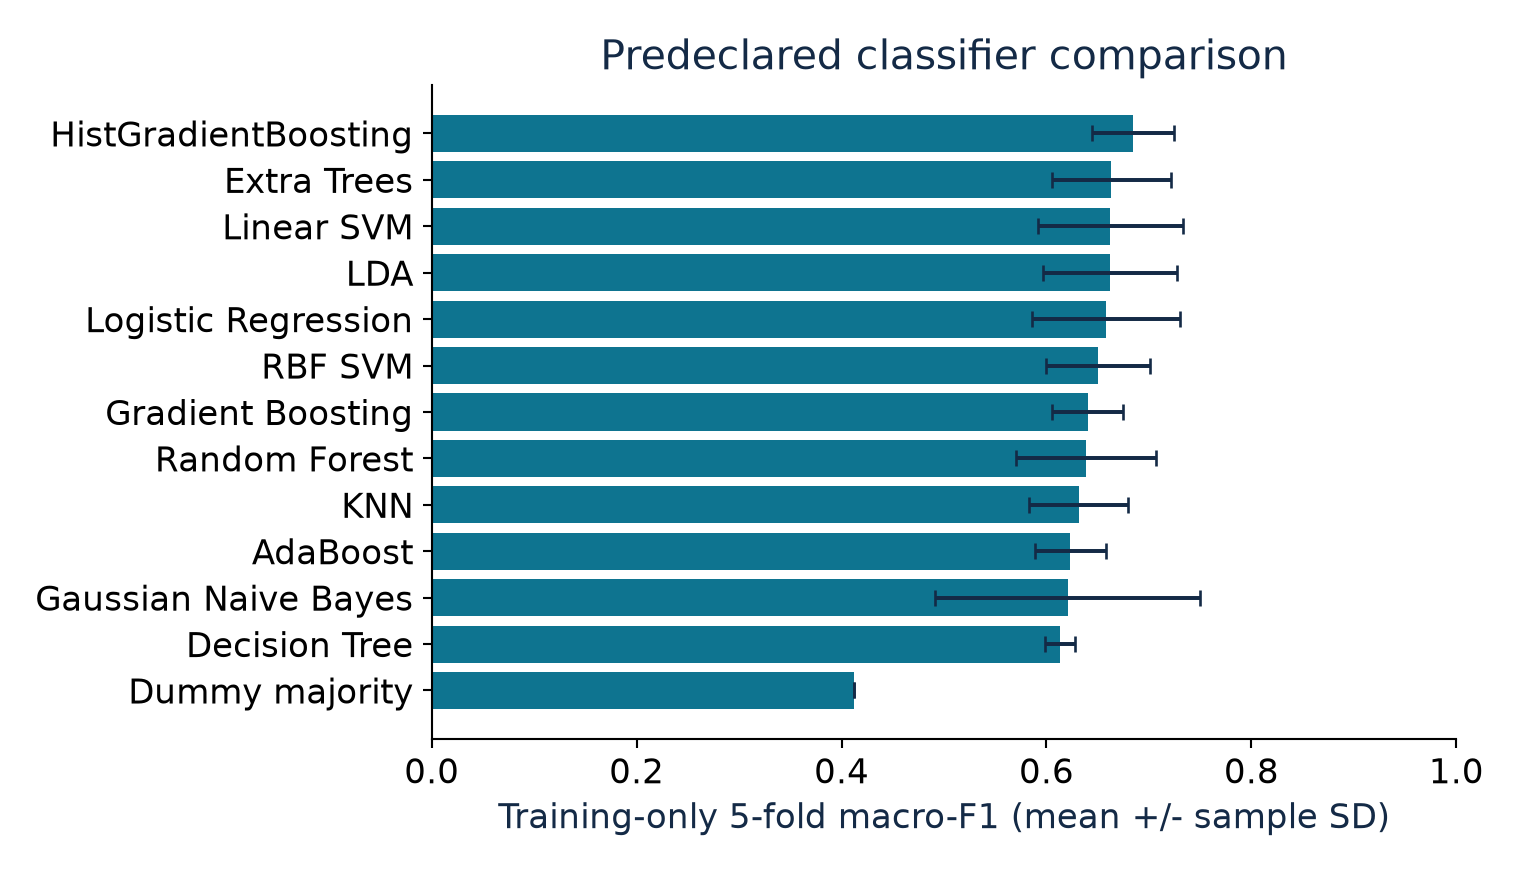

In [5]:
folds = list(StratifiedKFold(n_splits=5,shuffle=True,random_state=42).split(X_train,y_train))
rows = []
for name, estimator in models().items():
    scores, _ = evaluate_cv(estimator, X_train, y_train, folds)
    rows.append(dict(model=name, **scores))
comparison = pd.DataFrame(rows).sort_values(["cv_macro_f1_mean","model"],ascending=[False,True])
display(comparison.round(4))
selected_name = comparison.loc[comparison.model!="Dummy majority","model"].iloc[0]
print("Selected before test evaluation:", selected_name)
saved = pd.read_csv(root / "results/q2_model_comparison.csv").set_index("model")
for _, row in comparison.iterrows():
    assert np.isclose(row.cv_macro_f1_mean,saved.loc[row.model,"cv_macro_f1_mean"],atol=1e-12,rtol=0)
display(Image(filename=str(root / "figures/q2_model_comparison.png"), width=700))

## Measure capacity control without using the test set
Tree leaf/depth limits, KNN neighbor count and SVM C/gamma changes use development folds only. Larger training scores do not establish better generalization. The selected study scores may be optimistic because the same folds select the settings.

,family,configuration,full_train_macro_f1,cv_macro_f1_mean,cv_macro_f1_std,fold_train_macro_f1_mean,fold_generalization_gap
0,Decision Tree,"depth=None,leaf=1",1.0000,0.6128,0.0148,1.0000,0.3872
1,Decision Tree,"depth=2,leaf=1",0.4118,0.4722,0.0940,0.4989,0.0267
2,Decision Tree,"depth=3,leaf=1",0.6913,0.6003,0.0901,0.6732,0.0729
3,Decision Tree,"depth=5,leaf=1",0.7500,0.6242,0.0622,0.7576,0.1334
4,Decision Tree,"depth=8,leaf=1",0.8845,0.6398,0.0156,0.8961,0.2563
5,Decision Tree,"depth=None,leaf=5",0.8587,0.6347,0.0588,0.8484,0.2136
6,Decision Tree,"depth=None,leaf=15",0.7522,0.6594,0.0269,0.7473,0.0879
7,KNN,k=1,1.0000,0.6265,0.0157,1.0000,0.3735
8,KNN,k=3,0.8064,0.6213,0.0274,0.8095,0.1881
9,KNN,k=5,0.7546,0.6316,0.0483,0.7415,0.1099


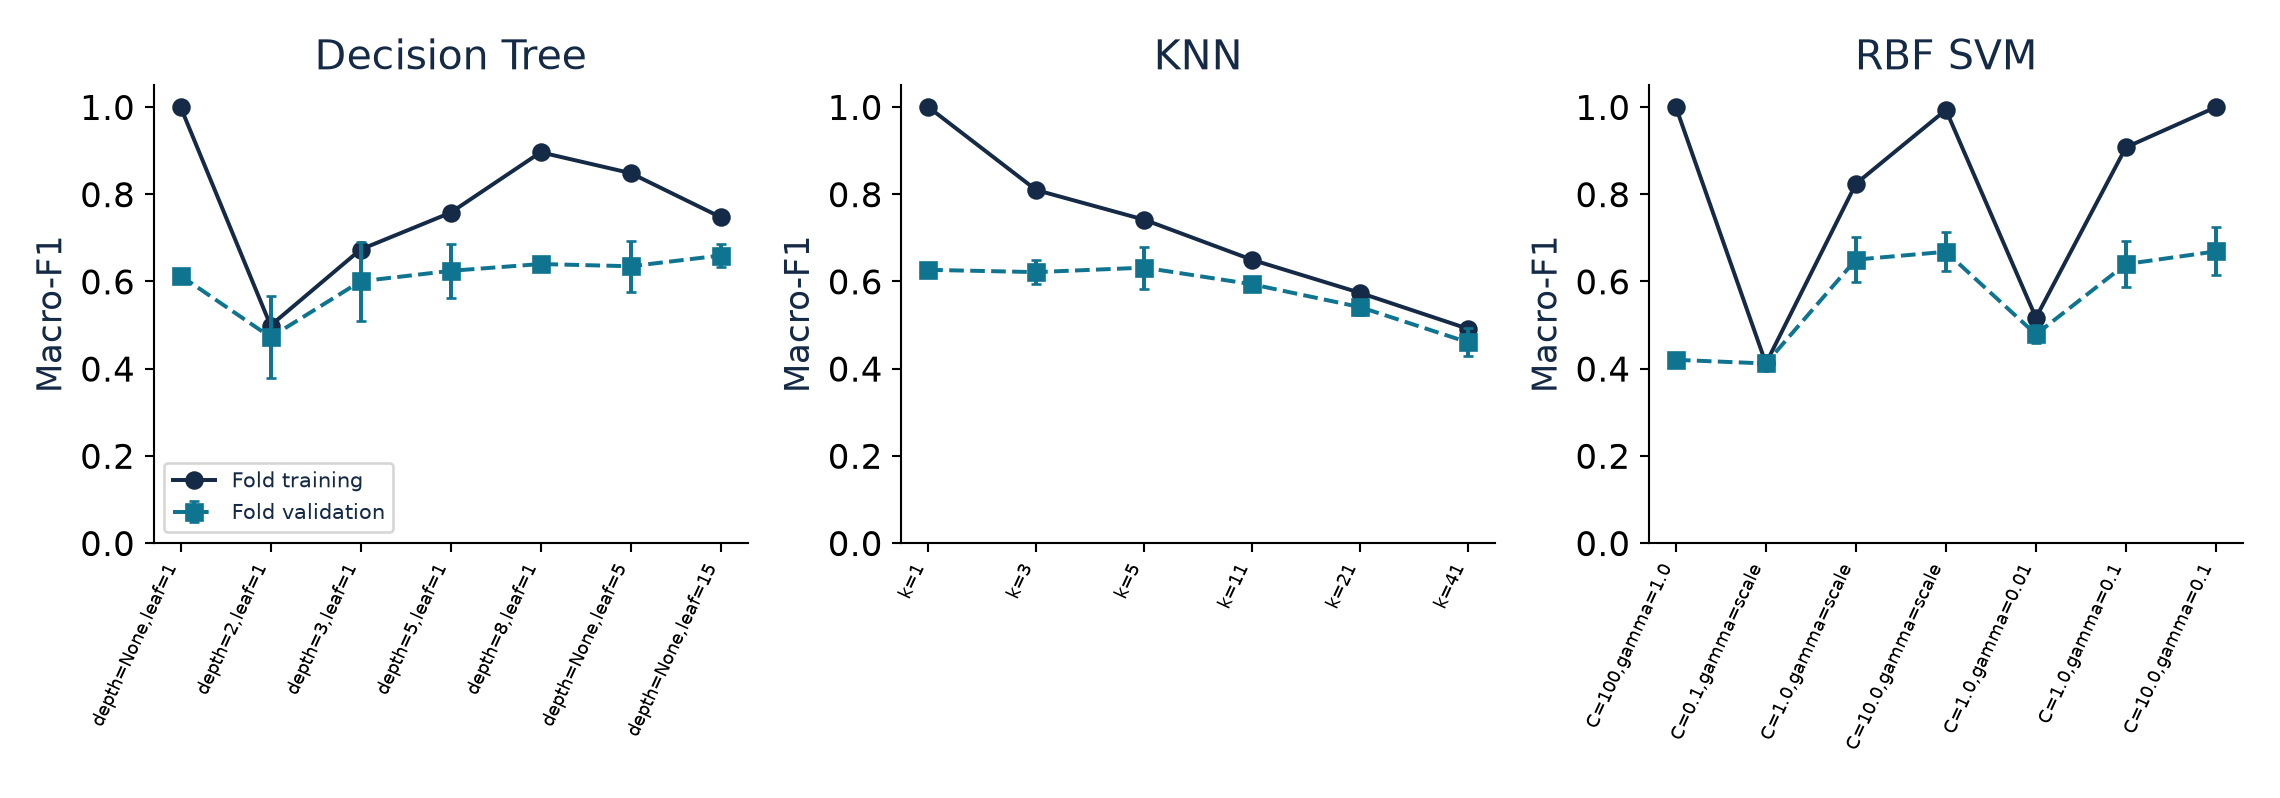

Decision Tree: depth=None,leaf=1 -> depth=None,leaf=15; CV change=+0.0465; gap change=-0.2992
KNN: k=1 -> k=5; CV change=+0.0050; gap change=-0.2635
RBF SVM: C=100,gamma=1.0 -> C=10.0,gamma=0.1; CV change=+0.2487; gap change=-0.2491


In [6]:
study, _ = run_studies(X_train,y_train,folds)
display(study.round(4))
display(Image(filename=str(root / "figures/q2_overfitting.png"), width=950))
for family in ["Decision Tree","KNN","RBF SVM"]:
    candidates = study[study.family==family]
    original = candidates.iloc[0]
    best = candidates.sort_values(["cv_macro_f1_mean","fold_generalization_gap"],ascending=[False,True]).iloc[0]
    print(f"{family}: {original.configuration} -> {best.configuration}; CV change={best.cv_macro_f1_mean-original.cv_macro_f1_mean:+.4f}; gap change={best.fold_generalization_gap-original.fold_generalization_gap:+.4f}")

## Final independent test evaluation
Only now does this notebook evaluate its already selected model. The larger benchmark script reports the fixed candidate test table once, without tuning in response.

accuracy    0.755000
macro_f1    0.687410
roc_auc     0.767857
dtype: float64

array([[122,  18],
       [ 31,  29]])

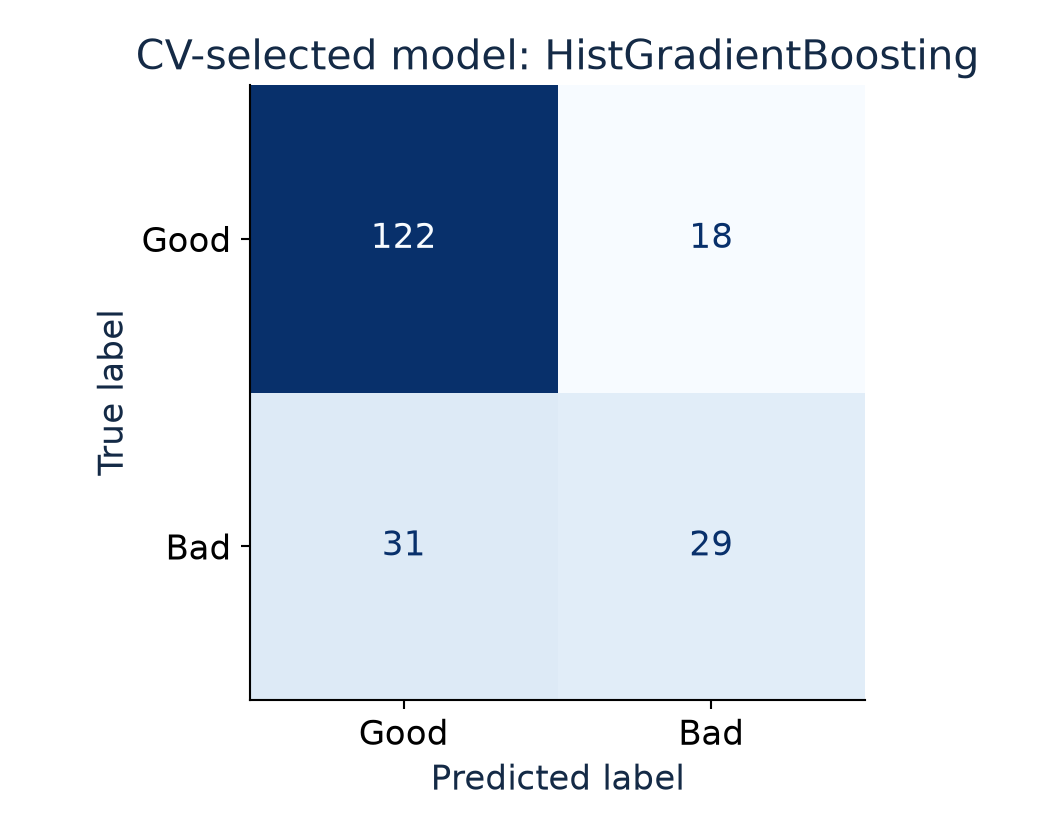

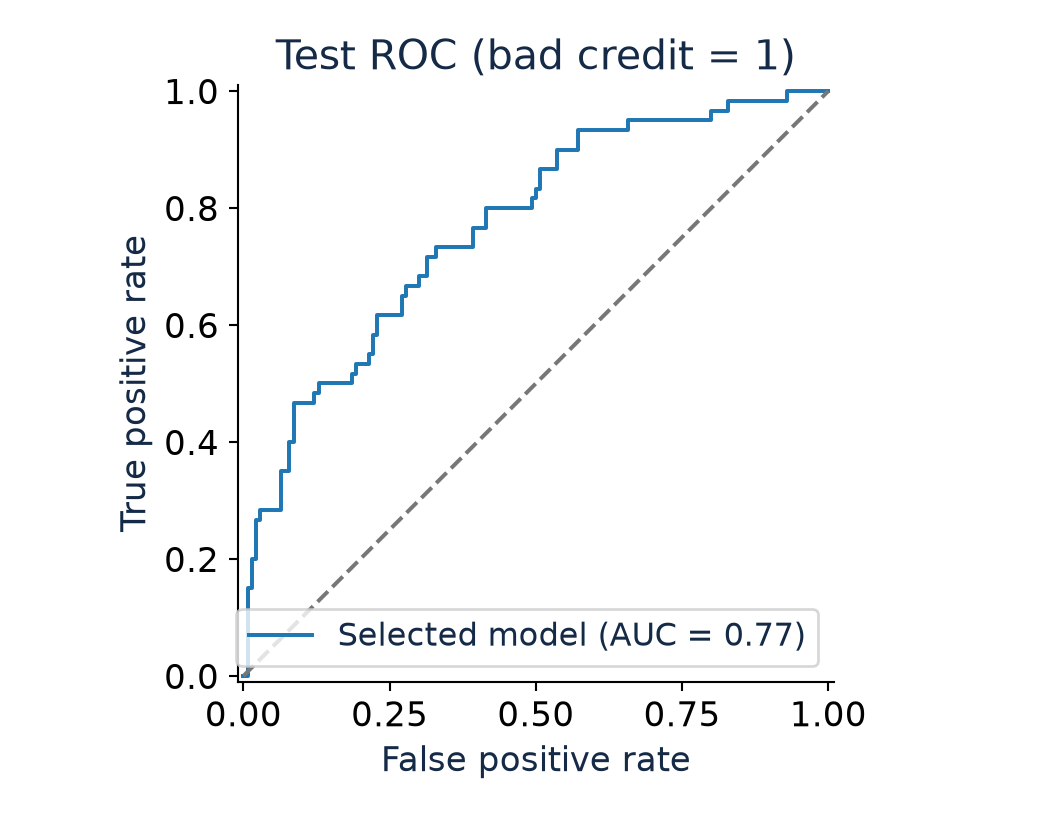

In [7]:
final_model = make_pipeline(models()[selected_name],X_train).fit(X_train,y_train)
pred = final_model.predict(X_test)
score = final_model.predict_proba(X_test)[:,1] if hasattr(final_model,"predict_proba") else final_model.decision_function(X_test)
measured = dict(accuracy=accuracy_score(y_test,pred),macro_f1=f1_score(y_test,pred,average="macro"),roc_auc=roc_auc_score(y_test,score))
display(pd.Series(measured));display(confusion_matrix(y_test,pred))
summary = json.loads((root / "results/q2_summary.json").read_text())
assert selected_name==summary["champion_selected_by_train_cv"]
for key, value in measured.items():
    assert np.isclose(value,summary["champion_metrics"]["test_"+key],rtol=0,atol=1e-12)
for name in ["q2_champion_confusion.png","q2_roc.png"]:
    display(Image(filename=str(root / "figures" / name), width=560))

## Interpretation and limits
HistGradientBoosting wins the predefined CV comparison, but has a substantial training/validation gap. Other models have higher test metrics on this particular split; they are not selected after viewing those outcomes. Leaf-size control reduces the tree gap, k=5 improves slightly over k=1, and extreme localized RBF settings overfit strongly. These descriptive capacity studies are not an unbiased estimate of tuning benefit.

The historical dataset includes sensitive attributes and an asymmetric cost matrix; this educational benchmark neither evaluates fairness nor optimizes lending decisions. Model-family controls beyond the three measured studies are theoretical suggestions in the report. All raw provenance, folds and predictions are packaged.